# Non-parametric, reference-free change point detection on single-neuron ISIs

Two detectors that need **only one spike train** (no pooled pre/post references, no fitted ISI distributions),
implemented in `CP_functions.py` and available in the pipeline as `method = 'edivisive_isi' | 'edivisive_time' | 'npid'`
(`cusum_analysis` / `simulate_w_cusum` in `CPA_with_AQUA.py`).

**1. e-divisive on the ISI series** (`edivisive_isi_cp`). The same energy cost as the population analysis (`CostEnergy`):
$\text{cost}(\text{seg}) = \sum_{i,j\in\text{seg}} |x_i-x_j| / n_\text{seg}$; the CP is the split with the largest cost drop
$\text{cost}(0,n)-\text{cost}(0,b)-\text{cost}(b,n)$, which compares *whole distributions* (energy distance), not just means.
Two ways to make the ISI "time series":
- `mode='isi'`: one point per ISI, $x_i = \text{ISI}_i$ (event-indexed);
- `mode='time'`: the ISI step function sampled every `dt_grid` = 10 ms: at each time the value is the ISI that contains it, so long ISIs weigh more (time-weighted).

`edivisive_split` computes all splits at once with a 2D prefix sum (O(n²)); it gives the same split as `rpt.Dynp` + `CostEnergy` (checked in `test_nonparametric.py`).

**2. Non-Parametric Isolate-Detect, NPID** (Anastasiou & Fryzlewicz 2025, arXiv:2504.21379; `npid`, `npid_cp`).
For every threshold $u$ the data become the binary sequence $B_t(u)=1\{X_t\le u\}$, and on an interval $[s,e]$
$$\tilde B^b_{s,e}(u)=\sqrt{\tfrac{e-b}{(b-s+1)(e-s+1)}}\sum_{t=s}^{b}B_t(u)-\sqrt{\tfrac{b-s+1}{(e-b)(e-s+1)}}\sum_{t=b+1}^{e}B_t(u),$$
i.e. a CUSUM of the empirical CDF at $u$. The statistic is $\max_b\max_u|\tilde B^b_{s,e}(u)|$ (a KS-type CUSUM).
**Isolate-Detect** checks intervals that grow by $\lambda$ = `points` from the right end ($[s, s+\lambda], [s, s+2\lambda],\dots$) and the left end
alternately, and stops at the first interval where the statistic exceeds $C\sqrt{\log n}$ ($C$ = 0.9). Because the intervals grow from the
ends, the first interval that triggers usually contains **one** change point (it is "isolated"). It then restarts on the remaining data,
so it finds **multiple** change points and decides by itself whether there are any.
The Python port is a literal port of `L_inf_norm` in the authors' R code (github.com/Anastasiou-Andreas/NPID) and gives the
same change points on 86 test series (last section).
For the pipeline (`npid_cp`) the CP is the strongest detection and score = its CUSUM / $\sqrt{\log n}$ (0 if nothing is detected);
`points = 3` because a trial has only a few tens of ISIs.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import seaborn as sns
import warnings
from sklearn.metrics import roc_auc_score
from CP_functions import (edivisive_isi_cp, isi_time_series, npid, npid_cp, llr_cp, spike_isis)
warnings.filterwarnings('ignore')
sns.set_context('notebook')

## Toy spike trains

Renewal processes with gamma ISIs (or a gamma mixture for bursting), at about the firing rate of the RS neuron (~4 Hz, i.e. ~40 ISIs per 10 s trial).
`T` = 10 s, change at `T_CP` = 5 s. `gamma(mean, cv)` is a frozen scipy distribution, so the oracle `llr_cp` can use the true densities.

In [2]:
T, T_CP = 10000., 5000.

def gamma(mean, cv):
    k = 1 / cv**2
    return stats.gamma(k, scale = mean / k)

class Mix:
    """Bursting: with probability p an intra-burst ISI, otherwise a long one. Has .rvs and .logpdf."""
    def __init__(self, p, d_short, d_long):
        self.p, self.a, self.b = p, d_short, d_long
    def rvs(self, size, random_state):
        r = random_state
        return np.where(r.random(size) < self.p, self.a.rvs(size, random_state = r), self.b.rvs(size, random_state = r))
    def logpdf(self, x):
        return np.logaddexp(np.log(self.p) + self.a.logpdf(x), np.log(1 - self.p) + self.b.logpdf(x))

def spike_train(dists, t_change, rng):
    """Spike times of a renewal process that switches ISI distribution at the times in t_change."""
    t, spikes, k = 0., [], 0
    bounds = list(t_change) + [T]
    while True:
        while k < len(bounds) - 1 and t >= bounds[k]:
            k += 1
        t += dists[k].rvs(1, random_state = rng)[0]
        if t >= T:
            return np.array(spikes)
        spikes.append(t)

SCENARIOS = {                      # (pre, post), all with mean ISI 250 ms before the change
    'rate change (250 -> 150 ms)':        (gamma(250, 0.5), gamma(150, 0.5)),
    'CV change (0.3 -> 1.2, same mean)':  (gamma(250, 0.3), gamma(250, 1.2)),
    'tonic -> bursting (same mean)':      (gamma(250, 0.3), Mix(0.5, gamma(10, 0.3), gamma(490, 0.3))),
    'no change':                          (gamma(250, 0.5), gamma(250, 0.5)),
}
rng = np.random.default_rng(1)
trains = {name: spike_isis(spike_train(d, [T_CP], rng)) for name, d in SCENARIOS.items()}

## How the methods work, one trial per scenario

- **Left:** the ISI series (dots: one per ISI, at the time the ISI ends; line: the 10 ms step-function series).
- **Middle:** e-divisive cost drop / n for every split, for both series. The CP is the maximum.
- **Right:** NPID on the per-ISI series (x axis = ISI index). The shaded band is the interval that isolated each detection; the dotted line is the true CP.

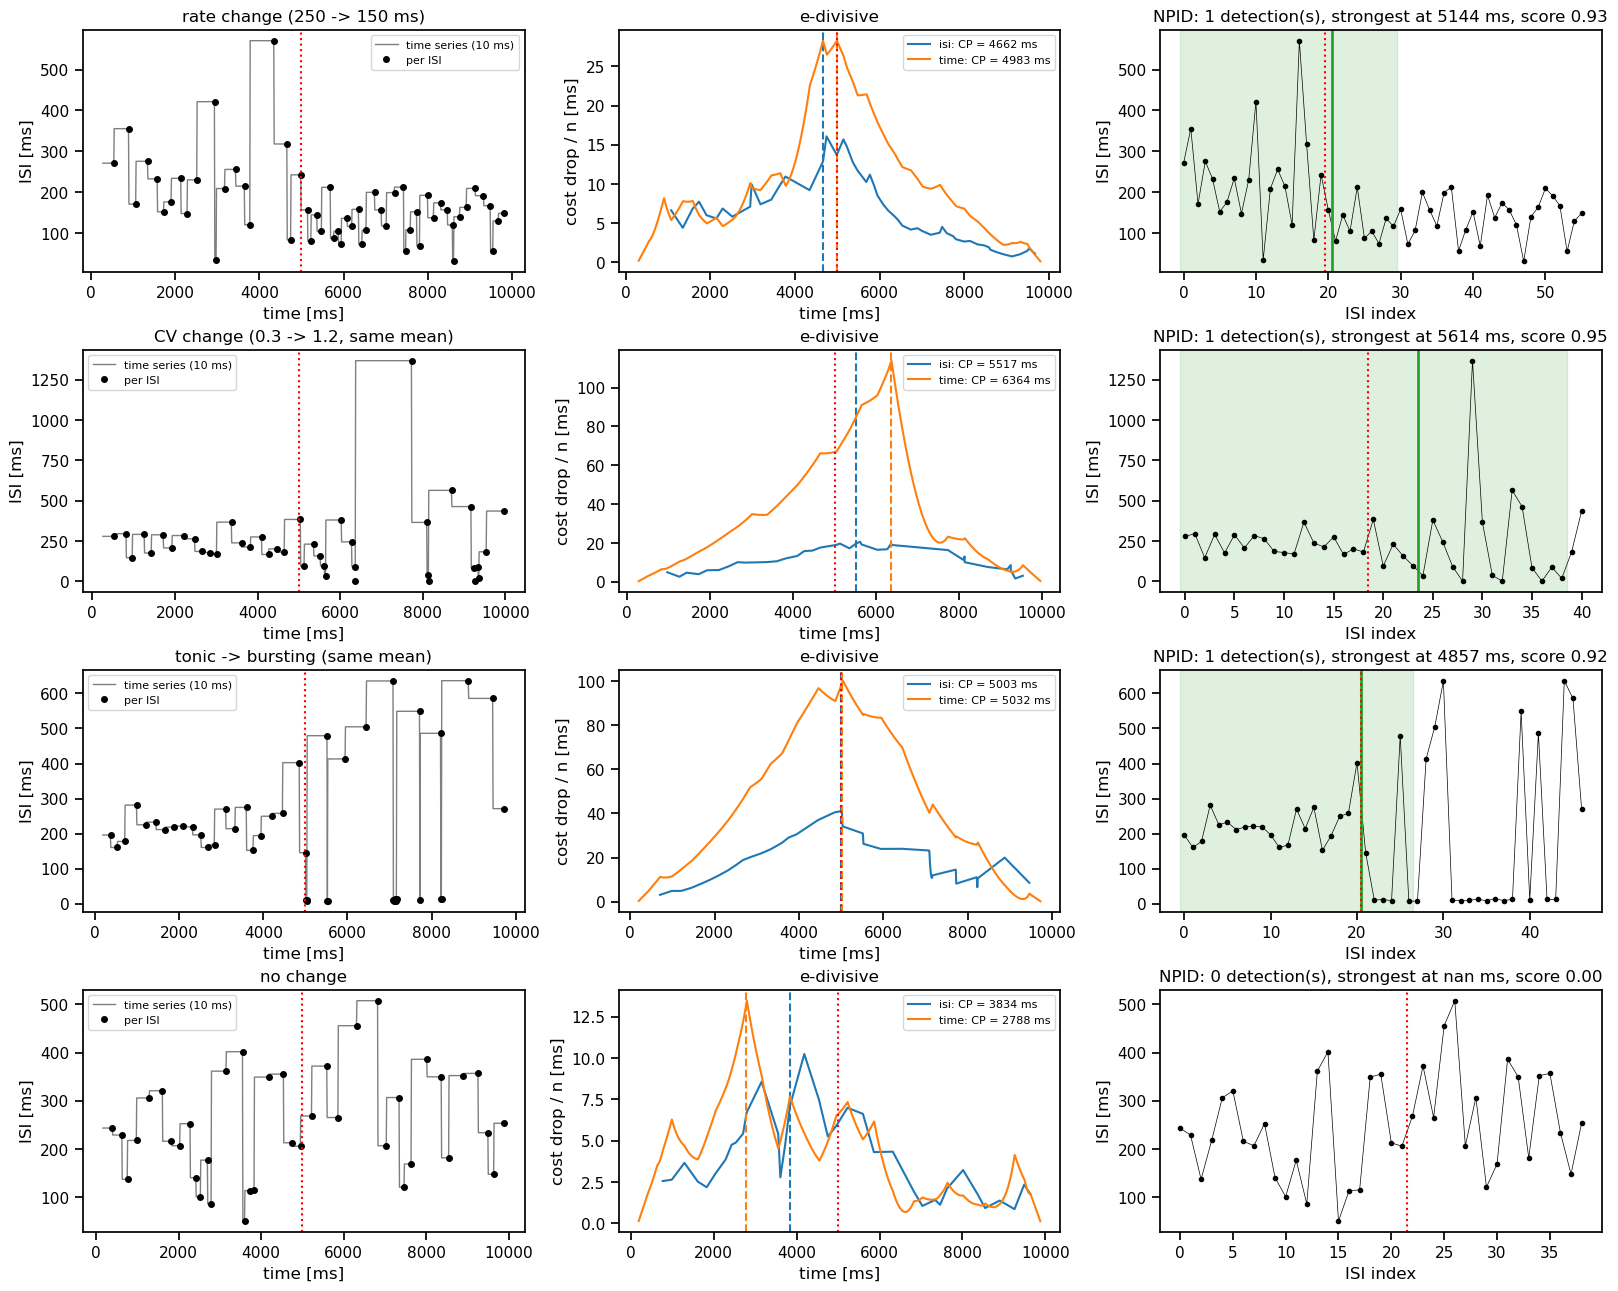

In [3]:
fig, axes = plt.subplots(len(trains), 3, figsize = (16, 3.2 * len(trains)), constrained_layout = True)
for row, (name, (isi, t_isi)) in zip(axes, trains.items()):
    x_t, t_grid = isi_time_series(isi, t_isi, 10.)
    row[0].plot(t_grid, x_t, color = 'C7', lw = 1, label = 'time series (10 ms)')
    row[0].plot(t_isi, isi, 'o', ms = 4, color = 'k', label = 'per ISI')
    row[0].set(title = name, xlabel = 'time [ms]', ylabel = 'ISI [ms]')

    for mode, c in (('isi', 'C0'), ('time', 'C1')):
        CP, score, t, drop = edivisive_isi_cp(isi, t_isi, mode, return_trace = True)
        row[1].plot(t, drop, color = c, label = f'{mode}: CP = {CP:.0f} ms')
        row[1].axvline(CP, color = c, ls = '--')
    row[1].set(xlabel = 'time [ms]', ylabel = 'cost drop / n [ms]', title = 'e-divisive')

    CP, score, (cps, st, ints) = npid_cp(isi, t_isi, return_trace = True)
    row[2].plot(isi, 'o-', ms = 3, color = 'k', lw = 0.5)
    for cp, (s, e) in zip(cps, ints):
        row[2].axvspan(s - 0.5, e + 0.5, color = 'C2', alpha = 0.15)
        row[2].axvline(cp + 0.5, color = 'C2', lw = 2)
    row[2].set(xlabel = 'ISI index', ylabel = 'ISI [ms]',
               title = f'NPID: {len(cps)} detection(s), strongest at {CP:.0f} ms, score {score:.2f}')

    i_true = np.searchsorted(t_isi, T_CP) - 0.5
    row[2].axvline(i_true, color = 'r', ls = ':')
    for ax in row[:2]:
        ax.axvline(T_CP, color = 'r', ls = ':')
    row[0].legend(fontsize = 8); row[1].legend(fontsize = 8)
plt.show()

## Performance over many trials

For each scenario and effect size, 200 independent trials. Effects:
- **rate**: post mean ISI = 250 / (1 + δ) (CV 0.5);
- **CV**: post CV = 0.5 + δ at the same mean (pre CV = 0.5);
- **burst**: a fraction δ of the post ISIs become intra-burst ISIs (~10 ms), the long ones are stretched to keep the mean at 250 ms.

δ = 0 is the no-change null. Methods: the three reference-free detectors, NPID with the R default λ = 15 as well, and the
**oracle** `llr_cp` with the *true* pre/post densities (it needs the distributions, which the others do not; no-change trials are scored against each alternative).

Metrics:
- **detection AUC**: how well the score separates change trials (δ > 0) from no-change trials (δ = 0) (0.5 = chance);
- **median |CP error|** over trials where a CP was returned;
- **NPID detection rate** at its built-in threshold (at δ = 0 this is the false-alarm rate).

In [4]:
def make(kind, d):
    pre = gamma(250, 0.5)
    if kind == 'rate':
        return pre, gamma(250 / (1 + d), 0.5)
    if kind == 'CV':
        return pre, gamma(250, 0.5 + d)
    if d == 0:
        return pre, pre
    return pre, Mix(d, gamma(10, 0.3), gamma((250 - d * 10) / (1 - d), 0.5))

EFFECTS = {'rate': [0, 0.1, 0.2, 0.4, 0.7, 1.0],
           'CV': [0, 0.2, 0.4, 0.7, 1.0, 1.5],
           'burst': [0, 0.1, 0.2, 0.3, 0.5, 0.7]}
METHODS = {
    'e-divisive (isi)':  lambda isi, t, pre, post: edivisive_isi_cp(isi, t, 'isi'),
    'e-divisive (time)': lambda isi, t, pre, post: edivisive_isi_cp(isi, t, 'time'),
    'NPID (λ=3)':        lambda isi, t, pre, post: npid_cp(isi, t, points = 3),
    'NPID (λ=15)':       lambda isi, t, pre, post: npid_cp(isi, t, points = 15),
    'oracle LLR':        lambda isi, t, pre, post: llr_cp(isi, t, pre, post),
}
N_TRIALS = 200
rng = np.random.default_rng(0)
rows, nulls = [], {}     # nulls[kind]: the no-change trains, to re-score with the oracle for each alternative
for kind, ds in EFFECTS.items():
    for d in ds:
        pre, post = make(kind, d)
        for rep in range(N_TRIALS):
            isi, t_isi = spike_isis(spike_train((pre, post), [T_CP], rng))
            if d == 0:
                nulls.setdefault(kind, []).append((isi, t_isi))
            for m, f in METHODS.items():
                CP, score = f(isi, t_isi, pre, post)
                rows.append((kind, d, rep, m, CP, score, len(isi)))
res = pd.DataFrame(rows, columns = ['change', 'effect', 'rep', 'method', 'CP', 'score', 'n ISI'])
res['abs error'] = (res['CP'] - T_CP).abs()
print(f"{len(res)} detections, median {res['n ISI'].median():.0f} ISIs per trial")

18000 detections, median 40 ISIs per trial


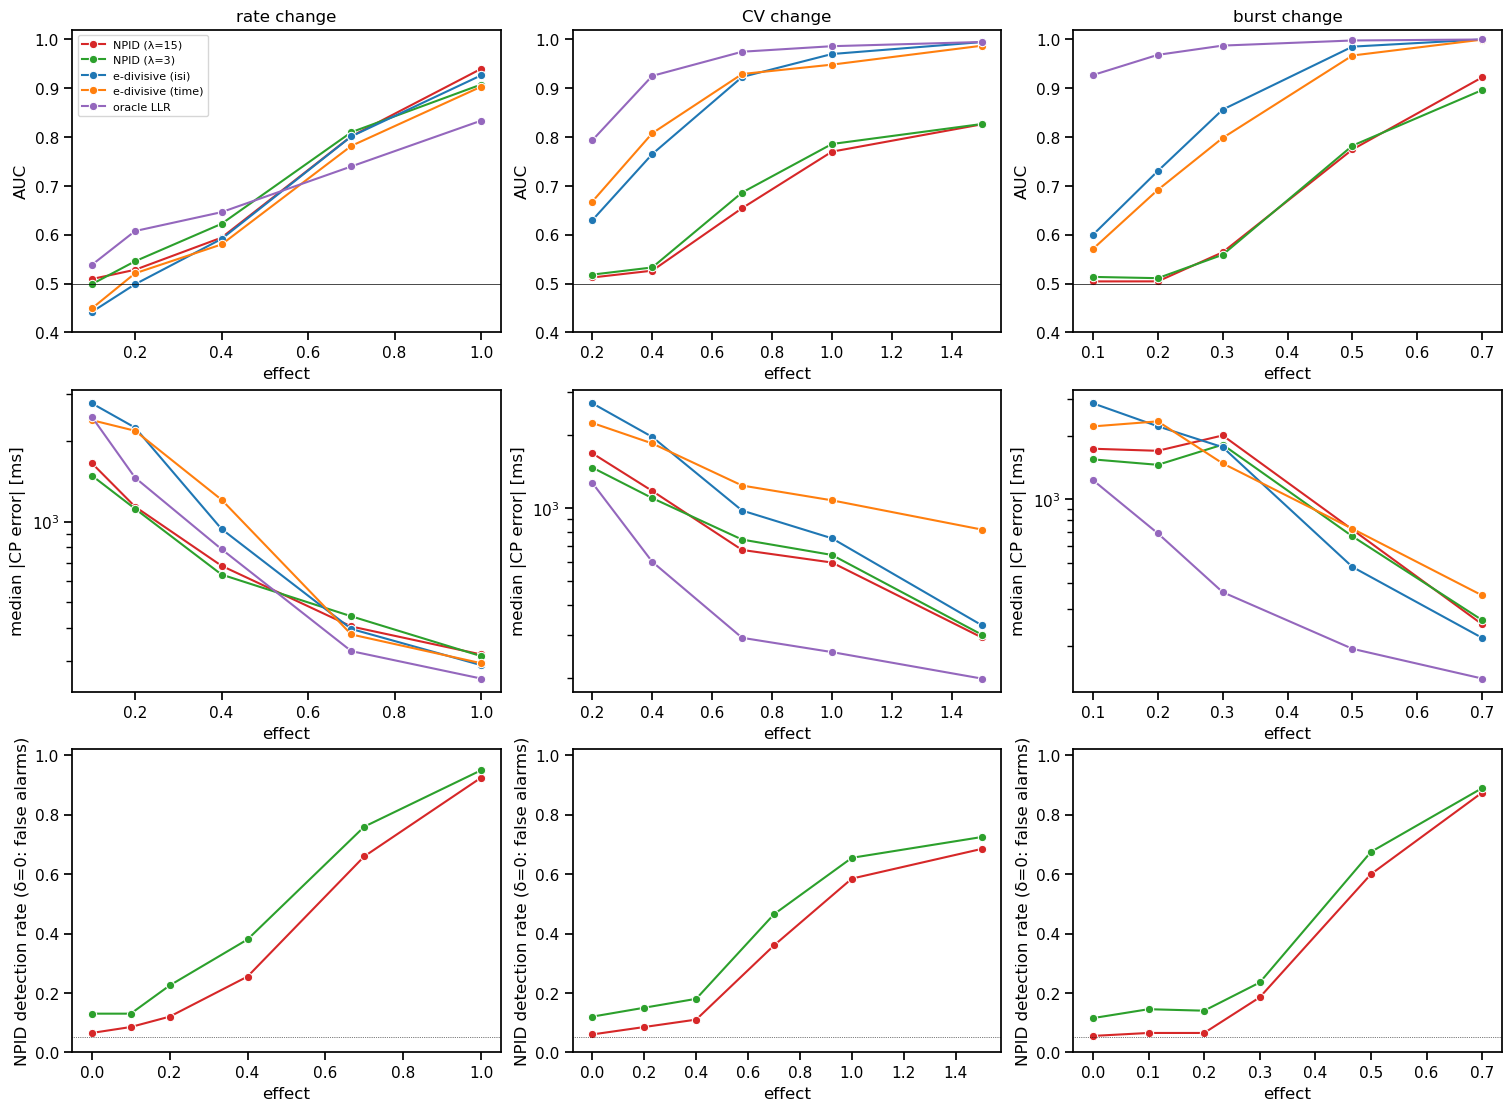

In [5]:
auc_rows = []
for (k, m), g in res.groupby(['change', 'method']):
    for d, gd in g[g.effect > 0].groupby('effect'):
        if m == 'oracle LLR':   # with pre = post its null score is 0; score the null trains against this alternative
            null = pd.Series([llr_cp(i, t, *make(k, d))[1] for i, t in nulls[k]]).fillna(-np.inf)
        else:
            null = g[g.effect == 0]['score'].fillna(-np.inf)      # no detection / no score ranks lowest
        s = gd['score'].fillna(-np.inf)
        auc_rows.append((k, m, d, roc_auc_score(np.r_[np.zeros(len(null)), np.ones(len(s))], np.r_[null, s])))
aucs = pd.DataFrame(auc_rows, columns = ['change', 'method', 'effect', 'AUC'])
errs = res[res.effect > 0].groupby(['change', 'method', 'effect'])['abs error'].median().rename('median |error|').reset_index()
det = res[res.method.str.startswith('NPID')].assign(detected = lambda x: x.CP.notna()) \
        .groupby(['change', 'method', 'effect'])['detected'].mean().reset_index()

kinds = list(EFFECTS)
fig, axes = plt.subplots(3, len(kinds), figsize = (5 * len(kinds), 11), constrained_layout = True)
pal = dict(zip(METHODS, sns.color_palette('tab10', len(METHODS))))
for j, k in enumerate(kinds):
    sns.lineplot(aucs[aucs.change == k], x = 'effect', y = 'AUC', hue = 'method', palette = pal, marker = 'o',
                 ax = axes[0, j], legend = j == 0)
    sns.lineplot(errs[errs.change == k], x = 'effect', y = 'median |error|', hue = 'method', palette = pal, marker = 'o',
                 ax = axes[1, j], legend = False)
    sns.lineplot(det[det.change == k], x = 'effect', y = 'detected', hue = 'method', palette = pal, marker = 'o',
                 ax = axes[2, j], legend = False)
    axes[0, j].set(title = f'{k} change', ylim = (0.4, 1.02)); axes[0, j].axhline(0.5, color = 'k', lw = 0.5)
    axes[1, j].set(ylabel = 'median |CP error| [ms]', yscale = 'log')
    axes[2, j].set(ylabel = 'NPID detection rate (δ=0: false alarms)', ylim = (0, 1.02)); axes[2, j].axhline(0.05, color = 'k', lw = 0.5, ls = ':')
axes[0, 0].legend(fontsize = 8)
plt.show()

In [6]:
summary = aucs.pivot_table(index = 'method', columns = ['change', 'effect'], values = 'AUC').round(2)
summary

change               CV                         burst                          \
effect              0.2   0.4   0.7   1.0   1.5   0.1   0.2   0.3   0.5   0.7   
method                                                                          
NPID (λ=15)        0.51  0.53  0.65  0.77  0.83  0.50  0.50  0.56  0.77  0.92   
NPID (λ=3)         0.52  0.53  0.69  0.79  0.83  0.51  0.51  0.56  0.78  0.90   
e-divisive (isi)   0.63  0.77  0.92  0.97  0.99  0.60  0.73  0.86  0.99  1.00   
e-divisive (time)  0.67  0.81  0.93  0.95  0.99  0.57  0.69  0.80  0.97  1.00   
oracle LLR         0.79  0.93  0.97  0.99  0.99  0.93  0.97  0.99  1.00  1.00   

change             rate                          
effect              0.1   0.2   0.4   0.7   1.0  
method                                           
NPID (λ=15)        0.51  0.53  0.59  0.80  0.94  
NPID (λ=3)         0.50  0.55  0.62  0.81  0.91  
e-divisive (isi)   0.44  0.50  0.59  0.80  0.93  
e-divisive (time)  0.45  0.52  0.58  0.78  0.90  
oracle LLR         0.54  0.61  0.65  0.74  0.83

**Reading the curves** (toy data, ~40 ISIs per trial):
- e-divisive compares whole ISI distributions, so it picks up CV and bursting changes at the same mean well; the per-ISI and time-grid
  versions are similar. The time-grid version weights long ISIs more, which helps detection a little for CV changes but makes the CP less precise.
- Its score (cost drop / n, in ms) scales with the ISI values, so a *rate increase* (shorter ISIs after the change) gets lower scores than
  the no-change trials at small effects (AUC < 0.5). Comparing scores across conditions with different rates needs care.
- NPID is more conservative: it decides by itself whether there is a change, with roughly 5% (λ=15) to 12% (λ=3) false alarms on these
  short trains at the default threshold (C = 0.9, tuned in the paper for longer series). When it detects, the location is about as precise
  as e-divisive. Its sensitivity is lower for distribution-shape changes because each threshold u is tested separately (max over u).
- The oracle LLR knows both true densities, so its **CP location** is the best of all. Its pipeline score (mean l after - before the CP)
  is not an optimal *detection* statistic though: no-change trials scored against a rate alternative also get large scores, so its
  AUC is not an upper bound (it falls below e-divisive for rate changes).

## Multiple change points

NPID is a multiple change point method; e-divisive here (and the pipeline) assumes one change. A train with changes at 3 s
(rate up), 6 s (CV up at the same mean) and 8 s (back to the start), at a higher rate (~10 Hz) so each segment has enough ISIs.

NPID λ=3: CPs at [3121. 6074. 7877.]
NPID λ=15: CPs at [3121. 6074. 7877.]


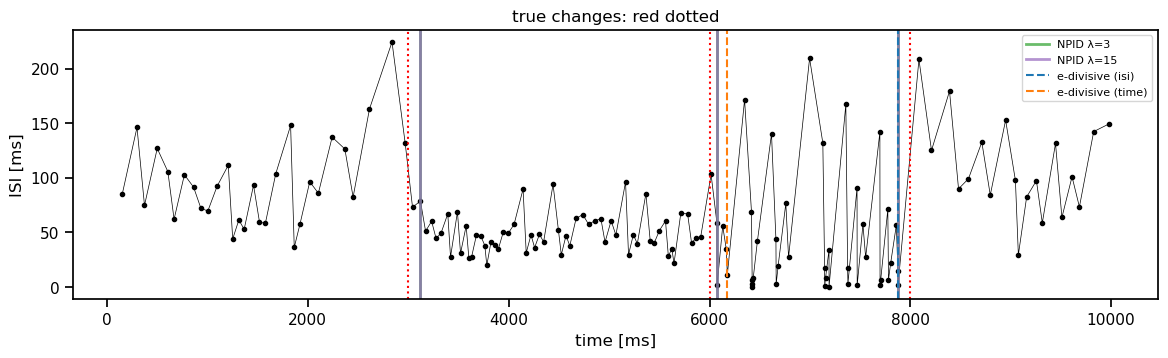

In [7]:
rng = np.random.default_rng(5)
dists = (gamma(100, 0.4), gamma(50, 0.4), gamma(50, 1.2), gamma(100, 0.4))
t_ch = [3000, 6000, 8000]
isi, t_isi = spike_isis(spike_train(dists, t_ch, rng))
fig, ax = plt.subplots(figsize = (14, 3.5))
ax.plot(t_isi, isi, 'o-', ms = 3, lw = 0.5, color = 'k')
for lam, c in ((3, 'C2'), (15, 'C4')):
    cps = npid(isi, points = lam)[0]
    for i, cp in enumerate(cps):
        ax.axvline(t_isi[cp], color = c, lw = 2, alpha = 0.7, label = f'NPID λ={lam}' if i == 0 else None)
    print(f'NPID λ={lam}: CPs at', np.round(t_isi[cps]))
for mode, c in (('isi', 'C0'), ('time', 'C1')):
    ax.axvline(edivisive_isi_cp(isi, t_isi, mode)[0], color = c, ls = '--', label = f'e-divisive ({mode})')
for t in t_ch:
    ax.axvline(t, color = 'r', ls = ':')
ax.set(xlabel = 'time [ms]', ylabel = 'ISI [ms]', title = 'true changes: red dotted'); ax.legend(fontsize = 8)
plt.show()

## Cross-check of the NPID port against the authors' R code

Runs `L_inf_norm` from `Main functions/main.R` (github.com/Anastasiou-Andreas/NPID) via `Rscript` and compares with `npid` for λ = 15 and 3.
Needs R with the CRAN package `IDetect` and internet access to download `main.R`; otherwise the cell is skipped.

In [8]:
import shutil, subprocess, tempfile, os, urllib.request

def r_check(series, url = 'https://raw.githubusercontent.com/Anastasiou-Andreas/NPID/main/Main%20functions/main.R'):
    if shutil.which('Rscript') is None:
        return print('Rscript not found: skipped')
    with tempfile.TemporaryDirectory() as d:
        try:
            urllib.request.urlretrieve(url, f'{d}/main.R')
        except Exception as e:
            return print(f'could not download main.R ({e}): skipped')
        for i, x in enumerate(series):
            np.savetxt(f'{d}/s{i}.txt', x)
        script = ('source(commandArgs(TRUE)[1]); for (f in commandArgs(TRUE)[-1]) { x <- scan(f, quiet = TRUE); '
                  'for (p in c(15, 3)) cat(paste(L_inf_norm(x, points = p)$changepoints, collapse = " "), "\n") }')
        out = subprocess.run(['Rscript', '-e', script, f'{d}/main.R'] + [f'{d}/s{i}.txt' for i in range(len(series))],
                             capture_output = True, text = True)
        if out.returncode:
            return print('R failed (is IDetect installed?):', out.stderr[-500:])
    r = [l.strip() for l in out.stdout.split('\n')][:2 * len(series)]   # one line per series and λ, empty = none
    py = [' '.join(map(str, npid(x, points = p)[0] + 1)) for x in series for p in (15, 3)]   # R is 1-based
    print(f'{sum(a == b for a, b in zip(r, py))} / {len(py)} identical')
    return pd.DataFrame({'R': r, 'Python': py})

rng = np.random.default_rng(7)
series = [np.concatenate([rng.gamma(rng.uniform(0.5, 5), rng.uniform(20, 200), rng.integers(8, 80))
                          for _ in range(rng.integers(1, 5))]) for _ in range(20)] + [trains[k][0] for k in trains]
r_check(series)

48 / 48 identical


,R,Python
0,101,101
1,101,101
2,68,68
3,68,68
4,,
5,,
6,70,70
7,32 70,32 70
8,53,53
9,51,51
